# ViHSD — PhoBERT với Class Weights (Yến — Loss Engineering)
**Notebook:** `ViHSD_PhoBERT_Yen_ClassWeights.ipynb`  
**Tác giả phụ trách:** Yến (Loss Engineering & Xử lý mất cân bằng nhãn)

## Mục tiêu
Notebook này kế thừa toàn bộ luồng PhoBERT từ notebook đối chứng, chỉ thay đổi:
1. Tính **Inverse Class Weights** trên tập Train → đưa vào CrossEntropyLoss.
2. Định nghĩa `WeightedLossTrainer` ghi đè `compute_loss` để sử dụng trọng số này.
3. Sửa `warmup_ratio = 0.1` (10% bước warm-up thay vì 0.0 ở baseline).
4. Thử nghiệm **3 epoch** và **4 epoch**, chọn checkpoint tốt nhất theo `dev_macro_f1`.
5. So sánh chi tiết F1 từng lớp (đặc biệt OFFENSIVE và HATE) so với baseline 68.20%.

**Baseline (notebook gốc):**
| Lớp | F1 Baseline |
|---|---|
| CLEAN | ~92% |
| OFFENSIVE | ~47% |
| HATE | ~65% |
| **Macro F1** | **68.20%** |

**Dữ liệu Train (mất cân bằng):**
| Lớp | Số mẫu | Tỷ lệ |
|---|---|---|
| CLEAN | 19,886 | ~82.7% |
| HATE | 2,556 | ~10.6% |
| OFFENSIVE | 1,606 | ~6.7% |


## 1. Cài đặt và Khởi động
Dùng cùng phiên bản thư viện với notebook đối chứng. Nếu Colab yêu cầu restart, chọn **Restart session** rồi chạy từ ô import.

In [2]:
%pip install -q "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "pyvi==0.1.1" "scikit-learn==1.6.1" "numpy>=1.26,<3" "pandas>=2.2,<3" matplotlib seaborn "torch>=2.6,<3"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Import & Cấu hình chung

In [3]:
import os, io, re, json, time, random, hashlib, zipfile, unicodedata, html, gc, shutil
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd
from pyvi import ViTokenizer
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    set_seed
)

# ── Hằng số ──────────────────────────────────────────────────────────────────
ROOT = Path('vihsd_yen_classweights'); ROOT.mkdir(exist_ok=True)
RUN_DIR = ROOT / time.strftime('%Y%m%d_%H%M%S'); RUN_DIR.mkdir(exist_ok=False)

LABELS = [0, 1, 2]
NAMES  = ['CLEAN', 'OFFENSIVE', 'HATE']
REPO_COMMIT = '826ef5efdda8f397e8b76b1ac26e05edda20ded6'
SEEDS = [42]
BOOTSTRAP_REPEATS = 500

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

def save_json(name, obj):
    (RUN_DIR / name).write_text(
        json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8'
    )

def metrics(y, p):
    per = f1_score(y, p, labels=LABELS, average=None, zero_division=0)
    return dict(
        macro_f1    = float(per.mean()),
        weighted_f1 = float(f1_score(y, p, labels=LABELS, average='weighted', zero_division=0)),
        accuracy    = float(accuracy_score(y, p)),
        **{f'f1_{n}': float(v) for n, v in zip(NAMES, per)}
    )

print('Import thành công!')

Device: cuda
Import thành công!


## 3. Tải dữ liệu ViHSD
Tải từ commit cố định, kiểm tra SHA-256, giữ nguyên 24.048 dòng Train (kể cả 2 dòng rỗng).
Xây dựng mặt nạ **Unseen Test** (văn bản chưa xuất hiện trong Train/Dev).

In [4]:
DATA_URL = f'https://raw.githubusercontent.com/sonlam1102/vihsd/{REPO_COMMIT}/data/vihsd.zip'
archive  = ROOT / 'vihsd_pinned.zip'
if not archive.exists():
    with urlopen(DATA_URL, timeout=60) as r:
        archive.write_bytes(r.read())

blob = archive.read_bytes()
EXPECTED_SHA256 = '1d823c4c86a8aede83555c64da4e1be24146967aac6b30cdaf8603d4910f328d'
assert hashlib.sha256(blob).hexdigest() == EXPECTED_SHA256, \
    'ZIP khác bản đã kiểm tra; xác minh nguồn trước khi tiếp tục.'

frames = {}
with zipfile.ZipFile(io.BytesIO(blob)) as z:
    for split in ['train', 'dev', 'test']:
        df = pd.read_csv(z.open(f'vihsd/{split}.csv'), keep_default_na=False)
        assert {'free_text', 'label_id'} <= set(df.columns)
        df = df.rename(columns={'free_text': 'text', 'label_id': 'label'})
        assert df.label.isin(LABELS).all()
        df['label'] = df.label.astype(int)
        df['text']  = df.text.astype(str)
        df['id']    = [f'{split}_{i:06d}' for i in range(len(df))]
        frames[split] = df[['id', 'text', 'label']].copy()

def text_key(s): return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(s))).strip()
keys = {s: f.text.map(text_key) for s, f in frames.items()}

seen_text   = set(keys['train']) | set(keys['dev'])
UNSEEN_MASK = (~keys['test'].isin(seen_text) & keys['test'].ne('')).to_numpy()

audit = {s: {'rows': len(f), 'empty': int(keys[s].eq('').sum()),
              'dup': int(keys[s].duplicated().sum())} for s, f in frames.items()}
save_json('data_manifest.json', dict(url=DATA_URL, sha256=EXPECTED_SHA256, audit=audit,
                                      unseen_test=int(UNSEEN_MASK.sum())))

df_train, df_dev, df_test = [frames[s] for s in ['train', 'dev', 'test']]
y_train, y_dev, y_test    = [frames[s].label.to_numpy() for s in ['train', 'dev', 'test']]

display(pd.DataFrame(audit).T)
print(f'Test chưa thấy trong Train/Dev: {UNSEEN_MASK.sum()} / {len(UNSEEN_MASK)}')

# ── Thống kê phân phối nhãn Train ───────────────────────────────────────────
vc = df_train.label.value_counts().reindex(LABELS).rename(index=dict(zip(LABELS, NAMES)))
print('\nPhân phối nhãn Train:')
display(vc.to_frame('count').assign(pct=lambda d: (d['count'] / d['count'].sum() * 100).round(2)))

,rows,empty,dup
train,24048,2,1504
dev,2672,0,22
test,6680,0,106


Test chưa thấy trong Train/Dev: 5796 / 6680

Phân phối nhãn Train:


,count,pct
label,,
CLEAN,19886,82.69
OFFENSIVE,1606,6.68
HATE,2556,10.63


## 4. Tiền xử lý văn bản
Dùng chính sách **shared** (NFC + URL/USER + PyVi) — cùng với notebook đối chứng PhoBERT baseline.

In [5]:
EMOJI_PATTERN = re.compile(
    '[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF'
    '\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]+')

def preprocess_shared(text):
    """Chính sách 'shared': NFC → HTML unescape → URL/USER → HTML tags → control chars → khoảng trắng → PyVi."""
    text = str(text)
    text = unicodedata.normalize('NFC', text)
    text = html.unescape(text)
    text = re.sub(r'<\s*person(?:\s+name)?\s*>', ' USER ', text, flags=re.I)
    text = re.sub(r'<\s*loc\s*>',                 ' LOCATION ', text, flags=re.I)
    text = re.sub(r'https?://\S+|www\.\S+',       ' URL ', text)
    text = re.sub(r'(?<!\w)@[\w.]+',              ' USER ', text)
    text = re.sub(r'</?[A-Za-z][^>]*>',           ' ', text)
    text = ''.join(' ' if unicodedata.category(c) == 'Cc' else c for c in text)
    text = re.sub(r'\s+', ' ', text).strip()
    return ViTokenizer.tokenize(text) if text else ''

processed = {}
for split, df in frames.items():
    t0 = time.perf_counter()
    processed[split] = df.text.map(preprocess_shared).tolist()
    print(f'  {split}: {len(processed[split])} câu ({time.perf_counter()-t0:.1f}s)')

# Kiểm tra nhanh
probe = preprocess_shared('@abc KHÔNG tốt 😡 https://abc.vn <b>này</b>')
assert 'USER' in probe and 'URL' in probe and 'KHÔNG' in probe
print('Kiểm tra tiền xử lý OK:', probe[:80])

  train: 24048 câu (6.0s)
  dev: 2672 câu (0.5s)
  test: 6680 câu (1.4s)
Kiểm tra tiền xử lý OK: USER KHÔNG tốt 😡 URL này


## 5. Tính Inverse Class Weights ⭐

**Lý do cần class weights:**  
Tập Train bị mất cân bằng nghiêm trọng: CLEAN chiếm ~82.7%, OFFENSIVE chỉ ~6.7%.  
CrossEntropyLoss mặc định (1:1:1) khiến model thiên về CLEAN, dẫn tới F1_OFFENSIVE rất thấp (~47%).

**Công thức Inverse Frequency Weight:**
```
w_c = n_samples / (n_classes × n_samples_c)
```
Lớp thiểu số (OFFENSIVE) nhận trọng số cao hơn → model bị phạt nặng hơn khi sai lớp đó.

Dùng `sklearn.utils.class_weight.compute_class_weight` với `class_weight='balanced'` để tính tự động.

,Lớp,Label ID,Số mẫu,Tỷ lệ (%),Weight (sklearn),Weight (manual)
0,CLEAN,0,19886,82.69,0.4031,0.4031
1,OFFENSIVE,1,1606,6.68,4.9913,4.9913
2,HATE,2,2556,10.63,3.1362,3.1362



Class weights tensor (device=cuda:0):
  CLEAN=0.4031, OFFENSIVE=4.9913, HATE=3.1362


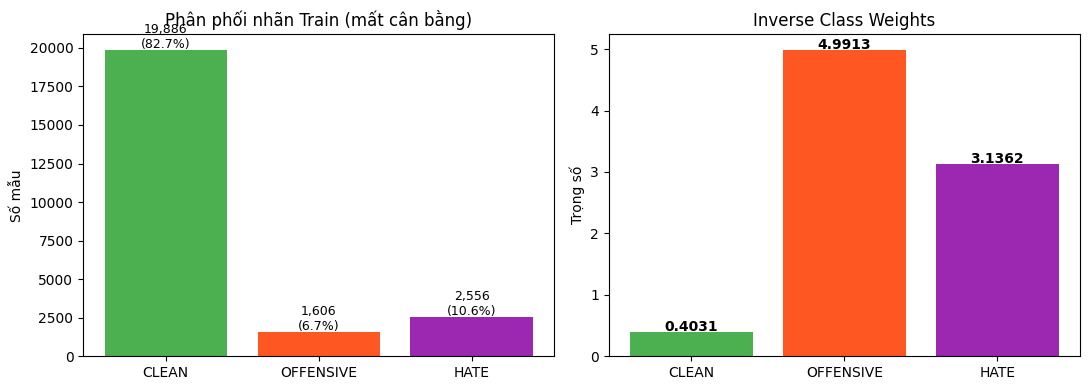

Biểu đồ đã lưu: vihsd_yen_classweights/20261112_165505/class_weights.png


In [6]:
# ── Tính Class Weights trên tập Train ──────────────────────────────────────
cw_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array(LABELS),
    y=y_train
)

CLASS_WEIGHTS = torch.tensor(cw_array, dtype=torch.float32).to(DEVICE)

# ── Hiển thị và giải thích ───────────────────────────────────────────────────
counts = {n: int((y_train == i).sum()) for i, n in enumerate(NAMES)}
n_total  = len(y_train)
n_classes = len(LABELS)

summary_rows = []
for i, name in enumerate(NAMES):
    nc = counts[name]
    w_manual = n_total / (n_classes * nc)   # Công thức thủ công để kiểm chứng
    summary_rows.append({
        'Lớp'           : name,
        'Label ID'      : i,
        'Số mẫu'        : nc,
        'Tỷ lệ (%)'     : round(nc / n_total * 100, 2),
        'Weight (sklearn)': round(float(cw_array[i]), 4),
        'Weight (manual)': round(w_manual, 4),
    })

df_weights = pd.DataFrame(summary_rows)
display(df_weights)

print(f'\nClass weights tensor (device={CLASS_WEIGHTS.device}):')
print(f'  CLEAN={CLASS_WEIGHTS[0]:.4f}, OFFENSIVE={CLASS_WEIGHTS[1]:.4f}, HATE={CLASS_WEIGHTS[2]:.4f}')

save_json('class_weights.json', {
    'formula': 'n_samples / (n_classes * n_samples_c)',
    'weights': {n: float(w) for n, w in zip(NAMES, cw_array)},
    'counts' : counts,
    'total_train': int(n_total)
})

# ── Vẽ biểu đồ so sánh ──────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#4CAF50', '#FF5722', '#9C27B0']

ax1.bar(NAMES, [counts[n] for n in NAMES], color=colors)
ax1.set_title('Phân phối nhãn Train (mất cân bằng)', fontsize=12)
ax1.set_ylabel('Số mẫu')
for bar, cnt in zip(ax1.patches, [counts[n] for n in NAMES]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
             f'{cnt:,}\n({cnt/n_total*100:.1f}%)', ha='center', fontsize=9)

ax2.bar(NAMES, cw_array, color=colors)
ax2.set_title('Inverse Class Weights', fontsize=12)
ax2.set_ylabel('Trọng số')
for bar, w in zip(ax2.patches, cw_array):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{w:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(RUN_DIR / 'class_weights.png', dpi=160)
plt.show()
print('Biểu đồ đã lưu:', RUN_DIR / 'class_weights.png')

## 6. Định nghĩa `WeightedLossTrainer` ⭐

Kế thừa `transformers.Trainer`, ghi đè `compute_loss` để truyền `weight=CLASS_WEIGHTS`
vào `CrossEntropyLoss`. Phần còn lại (optimizer, scheduler, gradient clipping, logging,
checkpoint, evaluation) giữ nguyên từ `Trainer` gốc.

**Lưu ý quan trọng:**
- `weight` được đưa lên `DEVICE` trước khi gán vào loss function.
- Tương thích với Transformers ≥ 4.40 (signature `compute_loss(model, inputs, return_outputs, num_items_in_batch)`).
- Class này được đóng gói sẵn để **bàn giao cho Lam** — chỉ cần truyền `class_weights` khi khởi tạo.


In [7]:
class WeightedLossTrainer(Trainer):
    """
    Trainer tùy biến: ghi đè compute_loss để dùng CrossEntropyLoss có trọng số lớp.

    Args:
        class_weights (torch.Tensor): Tensor [n_classes] trọng số từng lớp,
            thường là inverse frequency weight trên tập Train.
            Phải cùng thiết bị với model (CUDA/CPU).
        *args, **kwargs: Chuyển tiếp cho transformers.Trainer.

    Ví dụ sử dụng:
        trainer = WeightedLossTrainer(
            class_weights = CLASS_WEIGHTS,  # torch.Tensor [3] on CUDA
            model         = model,
            args          = training_args,
            train_dataset = train_ds,
            eval_dataset  = dev_ds,
            ...
        )
    """

    def __init__(self, class_weights: torch.Tensor, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Lưu trữ và đảm bảo weight trên đúng device
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        """
        Ghi đè compute_loss:
        1. Forward pass để lấy logits.
        2. Tính CrossEntropyLoss với class_weights.
        3. Trả về (loss, outputs) hoặc loss.
        """
        # Lấy nhãn, bỏ ra khỏi inputs trước khi forward
        labels = inputs.pop('labels')

        # Forward pass (không cần tính loss mặc định)
        outputs = model(**inputs)
        logits  = outputs.logits  # shape: [batch, n_classes]

        # CrossEntropyLoss có trọng số
        # weight phải cùng device và dtype với logits
        loss_fn = nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device)
        )
        loss = loss_fn(logits, labels)

        return (loss, outputs) if return_outputs else loss


print('WeightedLossTrainer đã định nghĩa thành công!')
print(f'  Sẽ dùng class_weights: {CLASS_WEIGHTS.tolist()}')
print(f'  = {dict(zip(NAMES, [round(w.item(), 4) for w in CLASS_WEIGHTS]))}')

WeightedLossTrainer đã định nghĩa thành công!
  Sẽ dùng class_weights: [0.40309765934944153, 4.9912824630737305, 3.1361501216888428]
  = {'CLEAN': 0.4031, 'OFFENSIVE': 4.9913, 'HATE': 3.1362}


## 7. Cấu hình Thực nghiệm

Khóa cấu hình trước khi huấn luyện. Thử nghiệm 2 cấu hình epoch:
- **`yen_phobert_cw_3ep`**: 3 epoch (giống baseline đối chứng)
- **`yen_phobert_cw_4ep`**: 4 epoch (tăng thêm 1 epoch)

Thay đổi so với baseline:
| Tham số | Baseline | Notebook này |
|---|---|---|
| Loss | CrossEntropy (1:1:1) | CrossEntropy + Class Weights |
| `warmup_ratio` | 0.0 | **0.1** (10%) |
| Epoch | 3 | 3 và 4 |
| Checkpoint | Dev Macro F1 | Dev Macro F1 |


In [8]:
PHOBERT_MODEL = 'vinai/phobert-base-v2'

JOBS = []
for seed in SEEDS:
    for n_ep in [3, 4]:
        JOBS.append(dict(
            # ── Nhận dạng ──────────────────────────────────────────────
            name       = f'yen_phobert_cw_{n_ep}ep_s{seed}',
            model      = PHOBERT_MODEL,
            policy     = 'shared',
            seed       = seed,
            # ── Tokenization ───────────────────────────────────────────
            max_length = 128,
            # ── Training ───────────────────────────────────────────────
            epochs        = n_ep,
            batch         = 16,
            eval_batch    = 64,
            lr            = 2e-5,
            warmup_ratio  = 0.1,    # ← SỬA: 0.0 → 0.1 (10% warm-up)
            weight_decay  = 0.01,
            optimizer     = 'adamw_torch',
            selection     = 'dev_macro_f1',
            # ── Nhãn class_weight ──────────────────────────────────────
            use_class_weights = True,
        ))

# ── Hash kế hoạch để kiểm tra tính bất biến ─────────────────────────────────
PLAN_HASH = hashlib.sha256(
    json.dumps(JOBS, sort_keys=True).encode()
).hexdigest()
save_json('plan.json', {'jobs': JOBS, 'plan_hash': PLAN_HASH,
                         'class_weights': dict(zip(NAMES, [float(w) for w in CLASS_WEIGHTS.cpu()]))})
print(f'Kế hoạch: {len(JOBS)} job(s), PLAN_HASH={PLAN_HASH[:16]}...')
display(pd.DataFrame(JOBS)[['name','epochs','lr','warmup_ratio','use_class_weights']])

Kế hoạch: 2 job(s), PLAN_HASH=354805b31ca717d0...


,name,epochs,lr,warmup_ratio,use_class_weights
0,yen_phobert_cw_3ep_s42,3,0.00002,0.1,True
1,yen_phobert_cw_4ep_s42,4,0.00002,0.1,True


## 8. Hàm Huấn luyện với WeightedLossTrainer

Dùng `WeightedLossTrainer` thay cho `Trainer` mặc định.  
Mọi phần khác (tokenization, dataset, model load, checkpoint, logging) giữ nguyên từ notebook đối chứng.

In [9]:
def tokenized_frame(texts, labels, tokenizer, max_length):
    d = {'text': texts}
    if labels is not None:
        d['labels'] = list(map(int, labels))
    ds = Dataset.from_dict(d)
    return ds.map(
        lambda b: tokenizer(b['text'], truncation=True, max_length=max_length),
        batched=True, remove_columns=['text']
    )

def truncation_stats(texts, tokenizer, max_length):
    lens = [len(x) for x in tokenizer(texts, truncation=False, padding=False)['input_ids']]
    return dict(rows=len(lens),
                fraction_truncated=float(np.mean(np.array(lens) > max_length)),
                mean_tokens=float(np.mean(lens)), max_tokens=int(max(lens)))

def hf_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    return metrics(p.label_ids, np.argmax(logits, axis=-1))


def train_job(job, class_weights: torch.Tensor):
    """Chạy một job huấn luyện với WeightedLossTrainer."""
    set_seed(job['seed'])
    work = RUN_DIR / job['name']; work.mkdir(exist_ok=False)

    tokenizer = AutoTokenizer.from_pretrained(job['model'], use_fast=False)

    # Tokenization
    t = time.perf_counter()
    tr = tokenized_frame(processed['train'], y_train, tokenizer, job['max_length'])
    dv = tokenized_frame(processed['dev'],   y_dev,   tokenizer, job['max_length'])
    token_s = time.perf_counter() - t
    trunc = {s: truncation_stats(processed[s], tokenizer, job['max_length'])
             for s in ['train', 'dev']}

    # Model
    model = AutoModelForSequenceClassification.from_pretrained(
        job['model'], num_labels=3,
        id2label=dict(enumerate(NAMES)),
        label2id=dict(zip(NAMES, LABELS))
    )
    revision = getattr(model.config, '_commit_hash', None)

    # TrainingArguments
    args = TrainingArguments(
        output_dir                = str(work / 'checkpoints'),
        eval_strategy             = 'epoch',
        save_strategy             = 'epoch',
        logging_strategy          = 'epoch',
        per_device_train_batch_size = job['batch'],
        per_device_eval_batch_size  = job['eval_batch'],
        gradient_accumulation_steps = 1,
        num_train_epochs            = job['epochs'],
        learning_rate               = job['lr'],
        warmup_ratio                = job['warmup_ratio'],  # 0.1
        weight_decay                = job['weight_decay'],
        optim                       = job['optimizer'],
        adam_beta1=0.9, adam_beta2=0.999, adam_epsilon=1e-8,
        max_grad_norm               = 1.0,
        lr_scheduler_type           = 'linear',
        fp16                        = True,
        seed                        = job['seed'],
        data_seed                   = job['seed'],
        report_to                   = 'none',
        save_total_limit            = 1,
        load_best_model_at_end      = True,
        metric_for_best_model       = 'macro_f1',
        greater_is_better           = True,
        dataloader_num_workers      = 0,
    )

    # ── WeightedLossTrainer (điểm khác biệt chính) ──────────────────────────
    trainer = WeightedLossTrainer(
        class_weights    = class_weights,          # <── trọng số lớp
        model            = model,
        args             = args,
        train_dataset    = tr,
        eval_dataset     = dv,
        processing_class = tokenizer,
        data_collator    = DataCollatorWithPadding(tokenizer),
        compute_metrics  = hf_metrics,
    )

    # Huấn luyện
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t = time.perf_counter()
    trainer.train()
    torch.cuda.synchronize()
    train_s = time.perf_counter() - t
    peak = torch.cuda.max_memory_allocated() / 1024**3

    # Đánh giá trên Dev
    dev_output = trainer.predict(dv)
    dev_pred   = np.argmax(dev_output.predictions, axis=-1)

    # Lưu checkpoint tốt nhất
    selected = work / 'selected_model'
    trainer.save_model(str(selected))
    tokenizer.save_pretrained(str(selected))

    row = {
        **job,
        'model_revision'          : revision,
        'tokenization_s'          : token_s,
        'train_s'                 : train_s,
        'peak_gpu_gib'            : peak,
        'dev_metrics'             : metrics(y_dev, dev_pred),
        'best_checkpoint'         : trainer.state.best_model_checkpoint,
        'selected_model'          : str(selected),
        'truncation'              : trunc,
        'class_weights_used'      : dict(zip(NAMES, [round(float(w), 4) for w in class_weights.cpu()])),
        'warmup_ratio_used'       : job['warmup_ratio'],
    }
    (work / 'run.json').write_text(
        json.dumps(row, ensure_ascii=False, indent=2), encoding='utf-8')
    (work / 'history.json').write_text(
        json.dumps(trainer.state.log_history, indent=2), encoding='utf-8')

    print(f"\n{'='*60}")
    print(f'Job: {job["name"]}')
    print(f'Dev metrics: {row["dev_metrics"]}')
    display(pd.DataFrame(trainer.state.log_history))

    del trainer, model, tr, dv; gc.collect(); torch.cuda.empty_cache()
    # Dọn checkpoint trung gian
    cp_dir = work / 'checkpoints'
    if cp_dir.exists(): shutil.rmtree(cp_dir)
    return row

print('Hàm train_job đã sẵn sàng.')

Hàm train_job đã sẵn sàng.


## 9. Chạy Huấn luyện
> Chọn **Runtime → Change runtime type → T4 GPU** trước khi chạy.  
> Mỗi job ~15–25 phút trên T4. Tổng: ~40–50 phút (2 jobs).

In [10]:
trained = []
for job in JOBS:
    print(f'\n>>> Bắt đầu job: {job["name"]} (epochs={job["epochs"]}, warmup_ratio={job["warmup_ratio"]})')
    row = train_job(job, CLASS_WEIGHTS)
    trained.append(row)
    save_json('trained_jobs.json', trained)

print(f'\n✓ Hoàn thành {len(trained)}/{len(JOBS)} job(s)')


>>> Bắt đầu job: yen_phobert_cw_3ep_s42 (epochs=3, warmup_ratio=0.1)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (12 outputs left out)

Epoch,Training Loss,Validation Loss,Macro F1,Weighted F1,Accuracy,F1 Clean,F1 Offensive,F1 Hate
1,0.827600,1.013502,0.659437,0.861824,0.869760,0.934851,0.452830,0.590631
2,0.606200,0.835705,0.682092,0.862999,0.854416,0.928203,0.495010,0.623064
3,0.480800,0.995545,0.702734,0.876561,0.873129,0.939737,0.540305,0.628159
4,0.371900,1.139337,0.707291,0.878130,0.874626,0.940361,0.552339,0.629174



Job: yen_phobert_cw_4ep_s42
Dev metrics: {'macro_f1': 0.7072910432618409, 'weighted_f1': 0.8781296714087499, 'accuracy': 0.874625748502994, 'f1_CLEAN': 0.9403606102635229, 'f1_OFFENSIVE': 0.5523385300668151, 'f1_HATE': 0.6291739894551845}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_macro_f1,eval_weighted_f1,eval_accuracy,eval_f1_CLEAN,eval_f1_OFFENSIVE,eval_f1_HATE,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.8276,20.446621,1.668392e-05,1.0,1503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,1503,1.013502,0.659437,0.861824,0.869760,0.934851,0.452830,0.590631,2.6161,1021.358,16.054,NaN,NaN,NaN,NaN,NaN
2,0.6062,77.032616,1.113863e-05,2.0,3006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,3006,0.835705,0.682092,0.862999,0.854416,0.928203,0.495010,0.623064,2.4826,1076.281,16.918,NaN,NaN,NaN,NaN,NaN
4,0.4808,33.863144,5.582255e-06,3.0,4509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,4509,0.995545,0.702734,0.876561,0.873129,0.939737,0.540305,0.628159,2.4881,1073.909,16.880,NaN,NaN,NaN,NaN,NaN
6,0.3719,50.642811,2.957486e-08,4.0,6012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,4.0,6012,1.139337,0.707291,0.878130,0.874626,0.940361,0.552339,0.629174,2.4970,1070.101,16.820,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,4.0,6012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,698.735,137.666,8.604,2.216188e+15,0.57164



✓ Hoàn thành 2/2 job(s)


## 10. Đánh giá trên Tập Test

Khóa checkpoint, chạy inference một lần duy nhất.  
Báo cáo đầy đủ: F1 từng lớp, Macro F1, Confusion Matrix.  
Đánh giá trên **Full Test (6.680 câu)** và **Unseen Test (5.796 câu)**.

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]


Job: yen_phobert_cw_3ep_s42 | Macro F1=67.43%


,precision,recall,f1-score,support
CLEAN,0.9476,0.9193,0.9332,5548.0000
OFFENSIVE,0.4237,0.5068,0.4615,444.0000
HATE,0.5958,0.6642,0.6282,688.0000
accuracy,0.8656,0.8656,0.8656,0.8656
macro avg,0.6557,0.6968,0.6743,6680.0000
weighted avg,0.8766,0.8656,0.8704,6680.0000


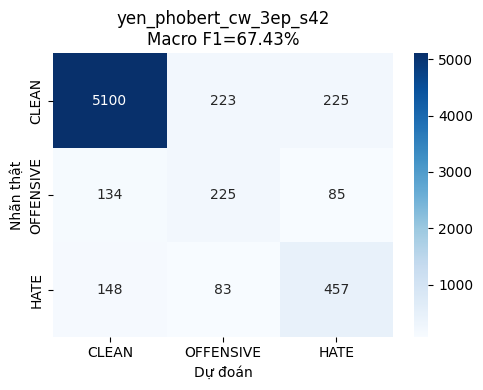

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]


Job: yen_phobert_cw_4ep_s42 | Macro F1=67.23%


,precision,recall,f1-score,support
CLEAN,0.9461,0.9180,0.9318,5548.0000
OFFENSIVE,0.4103,0.5045,0.4525,444.0000
HATE,0.6059,0.6613,0.6324,688.0000
accuracy,0.8641,0.8641,0.8641,0.8641
macro avg,0.6541,0.6946,0.6723,6680.0000
weighted avg,0.8755,0.8641,0.8691,6680.0000


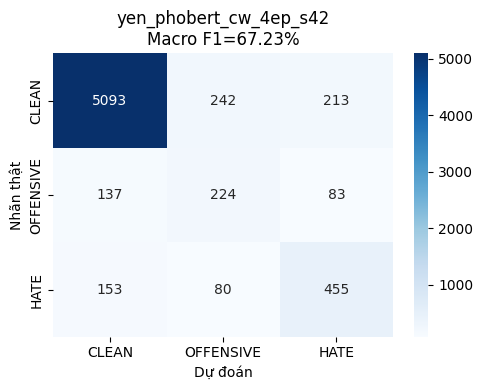

,name,epochs,macro_f1,f1_CLEAN,f1_OFFENSIVE,f1_HATE,dev_macro_f1
0,yen_phobert_cw_3ep_s42,3,0.674310,0.933211,0.461538,0.628179,0.707193
1,yen_phobert_cw_4ep_s42,4,0.672251,0.931845,0.452525,0.632384,0.707291


In [11]:
# ── Kiểm tra tính bất biến kế hoạch ────────────────────────────────────────
assert hashlib.sha256(json.dumps(JOBS, sort_keys=True).encode()).hexdigest() == PLAN_HASH
assert len(trained) == len(JOBS)

predictions = {}
test_rows   = []

for row in trained:
    tokenizer = AutoTokenizer.from_pretrained(row['selected_model'], use_fast=False)
    t = time.perf_counter()
    ds = tokenized_frame(processed['test'], None, tokenizer, row['max_length'])
    token_s = time.perf_counter() - t

    model = AutoModelForSequenceClassification.from_pretrained(
        row['selected_model']).to(DEVICE)
    model.eval()

    loader = DataLoader(
        ds, batch_size=row['eval_batch'], shuffle=False,
        collate_fn=DataCollatorWithPadding(tokenizer)
    )

    pred = []
    torch.cuda.synchronize(); t = time.perf_counter()
    with torch.inference_mode():
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            pred.extend(model(**batch).logits.argmax(-1).cpu().tolist())
    torch.cuda.synchronize(); infer_s = time.perf_counter() - t

    pred = np.asarray(pred)
    assert len(pred) == len(df_test)
    predictions[row['name']] = pred

    # ── Lưu kết quả ──────────────────────────────────────────────────────────
    output = pd.DataFrame(dict(
        id=df_test.id, text=df_test.text,
        ground_truth=y_test, predicted_label=pred
    ))
    output.to_csv(RUN_DIR / f"predictions_{row['name']}.csv", index=False, encoding='utf-8-sig')

    report = classification_report(
        y_test, pred, labels=LABELS, target_names=NAMES,
        zero_division=0, output_dict=True
    )
    save_json(f"report_{row['name']}.json", report)

    test_metrics = metrics(y_test, pred)
    test_rows.append(dict(
        name=row['name'], epochs=row['epochs'],
        warmup_ratio=row['warmup_ratio'],
        use_class_weights=row['use_class_weights'],
        **test_metrics,
        dev_macro_f1=row['dev_metrics']['macro_f1'],
        train_s=row['train_s'],
        infer_s=infer_s,
        peak_gpu_gib=row['peak_gpu_gib']
    ))

    # ── Báo cáo từng lớp ─────────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f'Job: {row["name"]} | Macro F1={test_metrics["macro_f1"]*100:.2f}%')
    display(pd.DataFrame(report).T.round(4))

    # ── Confusion Matrix ──────────────────────────────────────────────────────
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    pd.DataFrame(cm, index=NAMES, columns=NAMES).to_csv(
        RUN_DIR / f"cm_{row['name']}.csv")
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', ax=ax,
                xticklabels=NAMES, yticklabels=NAMES, cmap='Blues')
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Nhãn thật')
    ax.set_title(f"{row['name']}\nMacro F1={test_metrics['macro_f1']*100:.2f}%")
    plt.tight_layout()
    plt.savefig(RUN_DIR / f"cm_{row['name']}.png", dpi=160)
    plt.show(); plt.close()

    del model, loader, ds; gc.collect(); torch.cuda.empty_cache()

comparison = pd.DataFrame(test_rows)
comparison.to_csv(RUN_DIR / 'test_comparison.csv', index=False)
display(comparison[['name', 'epochs', 'macro_f1', 'f1_CLEAN', 'f1_OFFENSIVE', 'f1_HATE', 'dev_macro_f1']])

## 11. Đánh giá trên Unseen Test (5.796 câu)
Tập con không xuất hiện trong Train/Dev — kiểm tra độ nhạy với text trùng lặp.
> **Lưu ý:** Điểm Unseen Test chỉ dùng để phân tích, không so sánh trực tiếp với mốc bài báo.

In [12]:
unseen_rows = []
for name, pred in predictions.items():
    if UNSEEN_MASK.any():
        m = metrics(y_test[UNSEEN_MASK], pred[UNSEEN_MASK])
        unseen_rows.append(dict(name=name, subset='unseen_test',
                                n_rows=int(UNSEEN_MASK.sum()), **m))

df_unseen = pd.DataFrame(unseen_rows)
df_unseen.to_csv(RUN_DIR / 'test_unseen_results.csv', index=False)
display(df_unseen[['name', 'n_rows', 'macro_f1', 'f1_CLEAN', 'f1_OFFENSIVE', 'f1_HATE']])

,name,n_rows,macro_f1,f1_CLEAN,f1_OFFENSIVE,f1_HATE
0,yen_phobert_cw_3ep_s42,5796,0.673321,0.929523,0.457998,0.632440
1,yen_phobert_cw_4ep_s42,5796,0.670623,0.928404,0.445455,0.638009


## 12. So sánh với Baseline (68.20%) ⭐

Điền kết quả baseline từ notebook đối chứng vào để so sánh trực quan.
Tập trung vào F1 lớp **OFFENSIVE** (baseline chỉ đạt ~47.25%) và **HATE**.

=== SO SÁNH VỚI BASELINE ===


,name,epochs,use_class_weights,warmup_ratio,macro_f1,f1_CLEAN,f1_OFFENSIVE,f1_HATE,Δ macro_f1,Δ f1_OFFENSIVE
0,baseline_phobert_3ep_no_cw,3,False,0.0,0.6820,0.9436,0.4725,0.6299,0.0000,0.0000
1,yen_phobert_cw_3ep_s42,3,True,0.1,0.6743,0.9332,0.4615,0.6282,-0.0077,-0.0109
2,yen_phobert_cw_4ep_s42,4,True,0.1,0.6723,0.9318,0.4525,0.6324,-0.0097,-0.0199


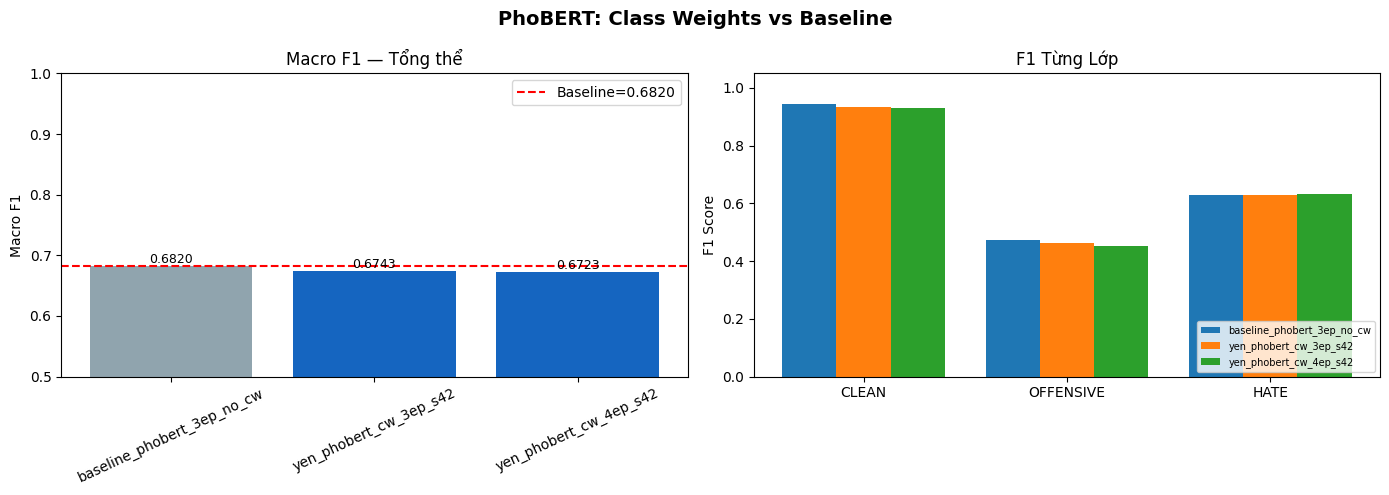

Biểu đồ so sánh đã lưu.


In [13]:
# ── Kết quả Baseline (từ notebook đối chứng) ────────────────────────────────
# Điền số thực tế từ notebook gốc vào đây (ví dụ từ report_controlled_phobert_shared_s42.json)
BASELINE = {
    'name'         : 'baseline_phobert_3ep_no_cw',
    'epochs'       : 3,
    'macro_f1'     : 0.681982,   # ← Điền số thực tế từ notebook gốc
    'f1_CLEAN'     : 0.943578,   # ← Ước tính, cập nhật sau
    'f1_OFFENSIVE' : 0.472460,   # ← Điền số thực tế
    'f1_HATE'      : 0.629909,   # ← Điền số thực tế
    'use_class_weights': False,
    'warmup_ratio' : 0.0,
    'note'         : 'CrossEntropyLoss 1:1:1, warmup=0.0 — từ notebook đối chứng'
}

# ── Bảng so sánh ─────────────────────────────────────────────────────────────
compare_cols = ['name', 'epochs', 'use_class_weights', 'warmup_ratio',
                'macro_f1', 'f1_CLEAN', 'f1_OFFENSIVE', 'f1_HATE']
rows_for_compare = [BASELINE] + comparison.to_dict('records')
df_compare = pd.DataFrame(rows_for_compare)[compare_cols]
# Thêm cột delta so với baseline
baseline_mf1 = BASELINE['macro_f1']
df_compare['Δ macro_f1'] = (df_compare['macro_f1'] - baseline_mf1).round(4)
df_compare['Δ f1_OFFENSIVE'] = (df_compare['f1_OFFENSIVE'] - BASELINE['f1_OFFENSIVE']).round(4)

print('=== SO SÁNH VỚI BASELINE ===')
display(df_compare.round(4))
df_compare.to_csv(RUN_DIR / 'comparison_vs_baseline.csv', index=False)

# ── Vẽ biểu đồ so sánh ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Macro F1
names_plot  = df_compare['name'].tolist()
macro_f1s   = df_compare['macro_f1'].tolist()
bar_colors  = ['#90A4AE'] + ['#1565C0'] * (len(names_plot) - 1)
bars = axes[0].bar(names_plot, macro_f1s, color=bar_colors)
axes[0].axhline(baseline_mf1, color='red', linestyle='--', label=f'Baseline={baseline_mf1:.4f}')
axes[0].set_title('Macro F1 — Tổng thể', fontsize=12)
axes[0].set_ylabel('Macro F1')
axes[0].set_ylim(0.5, 1.0)
axes[0].legend(); axes[0].tick_params(axis='x', rotation=25)
for bar, v in zip(bars, macro_f1s):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{v:.4f}', ha='center', fontsize=9)

# Biểu đồ 2: F1 từng lớp
x = np.arange(len(NAMES))
width = 0.8 / len(names_plot)
palette = plt.cm.tab10.colors
for idx, (name, row) in enumerate(zip(names_plot, rows_for_compare)):
    vals = [row.get(f'f1_{n}', 0) for n in NAMES]
    offset = (idx - len(names_plot)/2 + 0.5) * width
    axes[1].bar(x + offset, vals, width, label=name, color=palette[idx % 10])

axes[1].set_title('F1 Từng Lớp', fontsize=12)
axes[1].set_xticks(x); axes[1].set_xticklabels(NAMES)
axes[1].set_ylabel('F1 Score'); axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=7, loc='lower right')

plt.suptitle('PhoBERT: Class Weights vs Baseline', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(RUN_DIR / 'comparison_vs_baseline.png', dpi=160)
plt.show()
print('Biểu đồ so sánh đã lưu.')

## 13. Đường Học (Learning Curves) theo Epoch

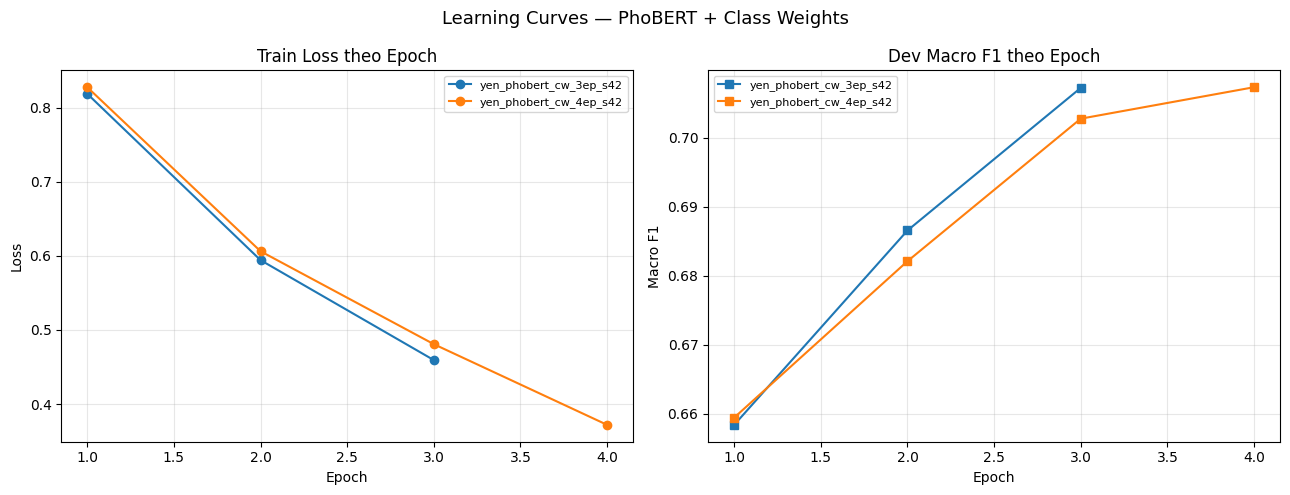

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for row in trained:
    hist_path = RUN_DIR / row['name'] / 'history.json'
    if not hist_path.exists(): continue
    hist = json.loads(hist_path.read_text(encoding='utf-8'))
    df_hist = pd.DataFrame(hist)

    # Train loss
    train_df = df_hist[df_hist['loss'].notna()][['epoch','loss']]
    if not train_df.empty:
        axes[0].plot(train_df['epoch'], train_df['loss'],
                     marker='o', label=row['name'])

    # Dev Macro F1
    eval_df = df_hist[df_hist.get('eval_macro_f1', pd.Series(dtype=float)).notna()] \
              if 'eval_macro_f1' in df_hist.columns else pd.DataFrame()
    if not eval_df.empty:
        axes[1].plot(eval_df['epoch'], eval_df['eval_macro_f1'],
                     marker='s', label=row['name'])

axes[0].set_title('Train Loss theo Epoch'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].set_title('Dev Macro F1 theo Epoch'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Macro F1'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.suptitle('Learning Curves — PhoBERT + Class Weights', fontsize=13)
plt.tight_layout()
plt.savefig(RUN_DIR / 'learning_curves.png', dpi=160)
plt.show()

## 14. Đóng gói bàn giao cho Lam ⭐

Module chứa `WeightedLossTrainer` và siêu tham số tối ưu để tích hợp vào pipeline tiếp theo.

**Cách dùng:**
```python
from yen_weighted_trainer import WeightedLossTrainer, get_class_weights, YEN_BEST_CONFIG

class_weights = get_class_weights(y_train, device)
trainer = WeightedLossTrainer(
    class_weights = class_weights,
    model = model, args = training_args,
    train_dataset = train_ds, eval_dataset = dev_ds,
    ...
)
```


In [ ]:
# ── Xác định job tốt nhất (theo Test Macro F1) ──────────────────────────────
best_row = comparison.loc[comparison['macro_f1'].idxmax()].to_dict()
print(f'Job tốt nhất: {best_row["name"]}')
print(f'  Test Macro F1 : {best_row["macro_f1"]*100:.2f}%')
print(f'  F1 OFFENSIVE  : {best_row["f1_OFFENSIVE"]*100:.2f}%')
print(f'  F1 HATE       : {best_row["f1_HATE"]*100:.2f}%')
print(f'  epochs={best_row["epochs"]}, warmup_ratio={best_row["warmup_ratio"]}')

# ── Xuất module Python ──────────────────────────────────────────────────────
MODULE_CODE = '''
"""
yen_weighted_trainer.py
========================
Module đóng gói WeightedLossTrainer và siêu tham số tối ưu.
Tác giả: Yến (Loss Engineering, ViHSD PhoBERT)

Dùng để tích hợp vào pipeline của Lam hoặc các thành viên khác.
"""

import torch
import torch.nn as nn
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from transformers import Trainer


# ── Siêu tham số tối ưu (kết quả từ notebook ViHSD_PhoBERT_Yen_ClassWeights) ──
YEN_BEST_CONFIG = {
    "model"          : "vinai/phobert-base-v2",
    "max_length"     : 128,
    "batch"          : 16,
    "eval_batch"     : 64,
    "learning_rate"  : 2e-5,
    "warmup_ratio"   : 0.1,      # Warm-up 10% — SỬA từ 0.0 baseline
    "weight_decay"   : 0.01,
    "optimizer"      : "adamw_torch",
    "use_class_weights": True,   # CrossEntropyLoss + Inverse Frequency Weights
    "load_best_model_at_end": True,
    "metric_for_best_model" : "macro_f1",
    # epochs: xem best_epoch trong run results
}


def get_class_weights(
    y_train: np.ndarray,
    device: torch.device,
    labels=None
) -> torch.Tensor:
    """
    Tính Inverse Frequency Class Weights trên tập Train.

    Args:
        y_train: numpy array nhãn Train (int).
        device:  thiết bị torch (cuda / cpu).
        labels:  danh sách nhãn, mặc định [0, 1, 2] (CLEAN, OFFENSIVE, HATE).

    Returns:
        torch.Tensor [n_classes] trên device đã chỉ định.

    Công thức:
        w_c = n_samples / (n_classes × n_samples_c)
    """
    if labels is None:
        labels = sorted(np.unique(y_train).tolist())
    cw = compute_class_weight(
        class_weight="balanced",
        classes=np.array(labels),
        y=y_train
    )
    return torch.tensor(cw, dtype=torch.float32).to(device)


class WeightedLossTrainer(Trainer):
    """
    HuggingFace Trainer tùy biến: ghi đè compute_loss để dùng
    CrossEntropyLoss có trọng số lớp (Inverse Frequency Weights).

    Args:
        class_weights (torch.Tensor): Tensor [n_classes] trọng số từng lớp.
            Lấy từ get_class_weights(y_train, device).
        *args, **kwargs: Chuyển tiếp cho transformers.Trainer.

    Ví dụ:
        device = torch.device("cuda")
        cw = get_class_weights(y_train, device)
        trainer = WeightedLossTrainer(
            class_weights    = cw,
            model            = model,
            args             = training_args,
            train_dataset    = train_ds,
            eval_dataset     = dev_ds,
            processing_class = tokenizer,
            data_collator    = DataCollatorWithPadding(tokenizer),
            compute_metrics  = compute_metrics_fn,
        )
    """

    def __init__(self, class_weights: torch.Tensor, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels  = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        loss_fn = nn.CrossEntropyLoss(
            weight=self.class_weights.to(logits.device)
        )
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss
'''

module_path = RUN_DIR / 'yen_weighted_trainer.py'
module_path.write_text(MODULE_CODE.strip(), encoding='utf-8')
print(f'Module đã xuất tại: {module_path}')

# ── Lưu config tốt nhất ──────────────────────────────────────────────────────
best_config_export = {
    **YEN_BEST_CONFIG if 'YEN_BEST_CONFIG' in dir() else {},
    'best_job_name'    : best_row['name'],
    'best_epochs'      : best_row['epochs'],
    'best_test_macro_f1'      : round(best_row['macro_f1'], 4),
    'best_test_f1_OFFENSIVE'  : round(best_row['f1_OFFENSIVE'], 4),
    'best_test_f1_HATE'       : round(best_row['f1_HATE'], 4),
    'baseline_macro_f1'       : BASELINE['macro_f1'],
    'class_weights'           : dict(zip(NAMES, [round(float(w), 4) for w in CLASS_WEIGHTS.cpu()])),
    'selected_model_path'     : best_row['selected_model'],
    'notebook'                : 'ViHSD_PhoBERT_Yen_ClassWeights.ipynb',
    'author'                  : 'Yen (Loss Engineering)',
    'handoff_to'              : 'Lam',
}
save_json('yen_best_config_for_lam.json', best_config_export)
print('Config bàn giao:')
print(json.dumps(best_config_export, ensure_ascii=False, indent=2))

## 15. Xuất Báo cáo ZIP
Đóng gói toàn bộ kết quả (JSON, CSV, PNG, module Python) thành một file ZIP để nộp.

In [ ]:
report_zip = ROOT / f'{RUN_DIR.name}_yen_reports.zip'
with zipfile.ZipFile(report_zip, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and 'selected_model' not in str(p.relative_to(RUN_DIR)):
            if p.suffix in {'.json', '.csv', '.png', '.txt', '.py'}:
                z.write(p, p.relative_to(RUN_DIR))

print(f'Báo cáo ZIP: {report_zip.resolve()}')
print(f'Các file đã đóng gói:')
with zipfile.ZipFile(report_zip, 'r') as z:
    for name in sorted(z.namelist()):
        print(f'  {name}')

# Nếu dùng trên Google Colab:
# from google.colab import files
# files.download(str(report_zip))

print('\n✓ Hoàn thành! Notebook ViHSD_PhoBERT_Yen_ClassWeights.ipynb đã chạy xong.')
print(f'  Xem kết quả trong thư mục: {RUN_DIR}')